# LangGraph로 배우는 상태 기반 챗봇

## LangGraph란?

LangGraph는 여러 작업을 **그래프 형태의 실행 구조**로 조직하고, 그 작업들이 공유하는 상태를 관리하는 프레임워크이자 실행 기반이다. 모델 자체가 아니라 모델 호출, 일반적인 데이터 처리, 도구 사용 등의 작업을 연결하는 역할을 한다.

여기서 그래프는 수치를 표현하는 차트나 지식 그래프가 아니다. 수학의 그래프 이론에서 따온 개념으로 작업을 나타내는 **노드**와 작업 사이의 연결을 나타내는 **엣지**로 이루어진 실행 구조다.  
순차 실행뿐 아니라 조건 분기와 반복을 표현할 수 있다. 자세한 배경은 [LangGraph 공식 개요](https://docs.langchain.com/oss/python/langgraph/overview)를 참고한다.

### LLM·LangChain·LangGraph의 역할 구분

| 구성 요소 | 핵심 역할 | 학습할 때 떠올릴 질문 |
| --- | --- | --- |
| LLM | 입력 문맥을 바탕으로 응답을 생성 | 무엇을 답할 것인가? |
| LangChain의 모델 인터페이스 | 모델 제공자와 상호작용하는 공통 인터페이스 제공 | 어떤 형태로 모델과 대화할 것인가? |
| LangGraph | 작업 연결과 상태 갱신을 관리 | 어떤 작업을 어떤 순서로 수행할 것인가? |

단일 질문에 답하는 기능만 필요하다면 모델 호출만으로도 충분할 수 있다. 그래프의 학습 가치는 답변 품질이 자동으로 좋아지는 데 있지 않고, 작업과 데이터의 관계를 명시적으로 설계할 수 있다는 데 있다.

## 노드·엣지·상태

| 개념 | 의미 | 상담 업무에 비유하면 |
| --- | --- | --- |
| 노드(Node) | 하나의 작업을 담당하는 실행 단위 | 문의 분류, 자료 조회, 답변 작성 |
| 엣지(Edge) | 다음에 수행할 작업을 연결하는 관계 | 분류 후 조회, 조회 후 답변 |
| 상태(State) | 실행 중 작업들이 공유하는 데이터의 현재 모습 | 문의 내용과 처리 결과가 담긴 상담 기록 |

노드는 일을 하고, 엣지는 다음 작업을 연결하며, 상태는 작업 사이에 필요한 정보를 전달한다.  
노드가 반드시 LLM을 포함할 필요는 없다. 숫자 계산이나 형식 검사도 노드가 될 수 있다. 상태의 필드 역시 대화 외에 조회 결과, 분류 값 등으로 확장할 수 있다.

**상태와 실행 위치는 다른 개념**이다. 상태는 어떤 데이터를 가지고 있는지를 나타내며, 실행 구조는 어떤 작업을 수행할지를 나타낸다. 이 둘을 구분하면 데이터 문제와 흐름 문제를 따로 생각할 수 있다. 기본 정의는 [Graph API 개요](https://docs.langchain.com/oss/python/langgraph/graph-api)를 참고한다.

In [2]:
from langchain_openai import ChatOpenAI

# 모델 초기화
model = ChatOpenAI(model="gpt-6-luna")
model.invoke('안녕하세요!')

AIMessage(content='안녕하세요! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 14, 'prompt_tokens': 9, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EXkVFif1A4gQzIINw07NG5BaJQzFu', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a12a5f-d763-7940-a9ad-aa5a5a13427f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 14, 'total_tokens': 23, 'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

## 상태 스키마와 갱신 규칙

### 상태 스키마: 데이터의 약속

스키마(schema)는 상태에 어떤 이름의 필드가 있으며 각 필드에 어떤 종류의 값이 들어갈지를 정의하는 약속이다. 명확한 스키마는 서로 다른 작업이 같은 데이터를 일관되게 이해하도록 돕는다.

### TypedDict와 Annotated

`TypedDict`는 딕셔너리의 키와 값 타입을 표현하는 타입 정의 방식이다. 객체가 특별한 저장 장치로 바뀌는 것이 아니며, 타입 표기만으로 실행 중 모든 값이 자동 검증되는 것도 아니다.

`Annotated`는 기본 타입에 추가 정보를 붙이는 표기다. 추가 정보의 의미는 이를 읽는 라이브러리가 결정한다. LangGraph에서는 상태 필드의 리듀서를 지정하는 데 활용한다.  
두 개념 모두 함수 호출의 결과보다는 **데이터 계약을 표현하는 타입 도구**로 이해하면 좋다.  
[Python 타입 힌트 공식 문서](https://docs.python.org/3/library/typing.html)

### add_messages와 단순 리스트 이어 붙이기의 차이

`add_messages`는 대화 메시지를 위한 병합 규칙이다. 새로운 ID의 메시지는 추가하고, 기존 메시지와 같은 ID의 업데이트는 해당 메시지를 대체한다.  
지원되는 메시지 입력을 LangChain 메시지 객체로 정규화하는 역할도 한다. 따라서 “언제나 뒤에 추가한다”는 설명만으로는 정확하지 않다.  
[공식 구현과 설명](https://github.com/langchain-ai/langgraph/blob/main/libs/langgraph/langgraph/graph/message.py)

| 상황 | 개념적 결과 |
| --- | --- |
| 새로운 메시지 ID | 대화 기록에 새 메시지 추가 |
| 기존 메시지와 동일한 ID | 해당 메시지의 내용 갱신 |
| 내용이 같지만 ID가 서로 다름 | 별개의 메시지로 취급될 수 있음 |

메시지 ID는 메시지의 식별자이지 사용자 ID나 대화방 ID가 아니다. 본문이 같다는 이유만으로 중복이 제거되는 것도 아니다.

> 타입 표기와 실제 값 구분: 이 실습의 코드는 `list[str]`로 표기되어 있지만, 메시지 정규화 후에는 `HumanMessage`, `AIMessage` 같은 객체가 들어갈 수 있다. 이 표기를 “실제 메시지는 항상 문자열”이라고 외우면 안 된다. 원본 코드는 유지하고, 선언된 타입과 실제 자료형을 구분해 학습한다.


In [3]:
from typing import Annotated # annotated는 타입 힌트를 사용할 때 사용하는 함수
from typing_extensions import TypedDict # TypedDict는 딕셔너리 타입을 정의할 때 사용하는 함수

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):
    """
    State 클래스는 TypedDict를 상속받습니다.

    속성:
        messages (Annotated[list[str], add_messages]): 메시지들은 "list" 타입을 가집니다.
       'add_messages' 함수는 이 상태 키가 어떻게 업데이트되어야 하는지를 정의합니다.
        (이 경우, 메시지를 덮어쓰는 대신 리스트에 추가합니다)
    """
    messages: Annotated[list[str], add_messages]

# StateGraph 클래스를 사용하여 State 타입의 그래프를 생성합니다
graph_builder = StateGraph(State)

## 노드 생성

In [4]:
def generate(state: State):
    """
    주어진 상태를 기반으로 챗봇의 응답 메시지를 생성합니다.

    매개변수:
    state (State): 현재 대화 상태를 나타내는 객체로, 이전 메시지들이 포함되어 있습니다.
		
    반환값:
    dict: 모델이 생성한 응답 메시지를 포함하는 딕셔너리. 
          형식은 {"messages": [응답 메시지]}입니다.
    """ 
    return {"messages": [model.invoke(state["messages"])]}

graph_builder.add_node("generate", generate)

In [5]:
graph_builder.add_edge(START, "generate")
graph_builder.add_edge("generate", END)    

graph = graph_builder.compile()

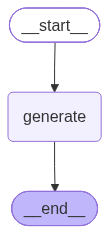

In [6]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception: 
    pass

In [7]:
response = graph.invoke({"messages": ["안녕하세요! 저는 조성민입니다"]})

print(type(response))
response

<class 'dict'>


{'messages': [HumanMessage(content='안녕하세요! 저는 조성민입니다', additional_kwargs={}, response_metadata={}, id='694a14c8-784b-4c54-ac5f-ebda68042087'),
  AIMessage(content='안녕하세요, 조성민님! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 55, 'prompt_tokens': 14, 'total_tokens': 69, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 30, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EXkVHmX3voLRtMiQXc2sLMxHLYBTD', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a12a5f-e981-74a1-833b-58efa8f60641-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 'output_tokens': 55, 'total_tokens': 69, 'inp

In [8]:
response["messages"].append("제 이름을 아시나요?")
graph.invoke(response)

{'messages': [HumanMessage(content='안녕하세요! 저는 조성민입니다', additional_kwargs={}, response_metadata={}, id='694a14c8-784b-4c54-ac5f-ebda68042087'),
  AIMessage(content='안녕하세요, 조성민님! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 55, 'prompt_tokens': 14, 'total_tokens': 69, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 30, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EXkVHmX3voLRtMiQXc2sLMxHLYBTD', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a12a5f-e981-74a1-833b-58efa8f60641-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 'output_tokens': 55, 'total_tokens': 69, 'inp

In [9]:
inputs = {"messages": [("human", "한국과 일본의 관계에 대해 자세히 알려줘")]}
for chunk, _ in graph.stream(inputs, stream_mode="messages"):
    print(chunk.content, end="")

# 한국과 일본의 관계

한국과 일본의 관계는 **경제·안보·문화에서는 서로 긴밀하게 연결되어 있지만, 식민지 지배의 역사와 영토 문제를 둘러싼 갈등이 반복되는 관계**입니다. 그래서 단순히 우호적이거나 적대적이라고 말하기 어렵습니다. 정부 간 관계가 나빠져도 민간 교류와 경제 협력은 이어지고, 반대로 협력이 늘어도 역사 문제는 쉽게 해소되지 않는 특징이 있습니다.

## 1. 역사적 흐름

- **고대부터 근대 이전까지:** 한반도와 일본 열도 사이에는 교역·문화 교류가 이어졌습니다. 한반도를 통한 문자, 불교, 기술 등의 전래도 중요한 역사적 관계의 일부입니다. 반면 임진왜란(1592년)과 정유재란(1597년)처럼 큰 충돌도 있었습니다.
- **근대와 식민지 지배:** 일본은 19세기 후반부터 한반도에 대한 영향력을 확대했고, 1910년 한국을 강제로 병합했습니다. 한국은 1945년 일본의 패전과 함께 식민 지배에서 벗어났습니다. 이 시기의 지배와 전쟁 동원, 위안부 문제 등은 지금도 양국 관계에 깊은 영향을 줍니다.
- **1965년 국교 정상화:** 한국과 일본은 국교를 정상화하고 「한일기본조약」과 청구권 관련 협정을 맺었습니다. 일본은 한국에 경제협력 자금 등을 제공했고, 양국 간 공식 관계가 시작됐습니다. 다만 이 협정이 개인 피해자의 배상 청구권까지 어떻게 다루는지에 대해 양국의 해석은 다릅니다. 이 차이는 오늘날 강제동원 문제의 핵심 쟁점 중 하나입니다.
- **1998년 공동선언:** 김대중 대통령과 오부치 게이조 총리는 미래지향적 관계를 만들겠다는 공동선언을 발표했습니다. 일본 대중문화 개방과 문화 교류 확대에도 중요한 계기가 됐습니다.
- **2018~2019년 갈등:** 한국 대법원의 강제동원 관련 판결 이후 일본의 수출관리 조치와 한국의 대응이 이어지며 관계가 크게 악화됐습니다.
- **2023년 이후 개선 흐름:** 한국 정부가 강제동원 피해자 배상을 위한 제3자 변제 방안을 발표했고, 양국은 수출관리 갈등을 풀고 안보 협력을 복원하는